In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from datetime import datetime

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import os
import copy
import random

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Hourly Temperature Forecasting with LSTMs

Forecast next-hour air temperature from the previous **72 hours** of weather measurements (pressure, temperature, humidity, wind speed and direction), using a stacked LSTM in PyTorch. The model is benchmarked against naive forecasts and a bidirectional variant.

**Dataset:** [Jena Climate 2009–2016](https://www.kaggle.com/datasets/stytch16/jena-climate-2009-2016), recorded by the Max Planck Institute for Biogeochemistry weather station in Jena, Germany. The CSV is included in `data/`.

## 1. Load Dataset

In [2]:
df = pd.read_csv("data/jena_climate_2009_2016.csv")
print(f"Dataset shape: {df.shape}")
print(f"Time range: {df['Date Time'].iloc[0]} to {df['Date Time'].iloc[-1]}")
df.head()


Dataset shape: (420551, 15)
Time range: 01.01.2009 00:10:00 to 01.01.2017 00:00:00


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


## 2. EDA

### 2.1 Dataset Overview

In [3]:
# Dataset overview

# Parse datetime
df['Date Time'] = pd.to_datetime(df['Date Time'], format='%d.%m.%Y %H:%M:%S')

print("=== Dataset Info ===")
print(f"Number of samples: {len(df)}")
print(f"Number of features: {df.shape[1]}")
print(f"Sampling interval: 10 minutes")
print(f"Time span: {df['Date Time'].iloc[0]} to {df['Date Time'].iloc[-1]}")
print(f"\n=== Missing Values ===")
print(df.isnull().sum())
print(f"\n=== Statistical Summary ===")
df.describe().round(2)

=== Dataset Info ===
Number of samples: 420551
Number of features: 15
Sampling interval: 10 minutes
Time span: 2009-01-01 00:10:00 to 2017-01-01 00:00:00

=== Missing Values ===
Date Time          0
p (mbar)           0
T (degC)           0
Tpot (K)           0
Tdew (degC)        0
rh (%)             0
VPmax (mbar)       0
VPact (mbar)       0
VPdef (mbar)       0
sh (g/kg)          0
H2OC (mmol/mol)    0
rho (g/m**3)       0
wv (m/s)           0
max. wv (m/s)      0
wd (deg)           0
dtype: int64

=== Statistical Summary ===


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
count,420551,420551.00,420551.00,420551.00,420551.00,420551.00,420551.00,420551.00,420551.00,420551.00,420551.00,420551.00,420551.00,420551.00,420551.00
mean,2012-12-30 06:26:51.498724,989.21,9.45,283.49,4.96,76.01,13.58,9.53,4.04,6.02,9.64,1216.06,1.70,3.06,174.74
min,2009-01-01 00:10:00,913.60,-23.01,250.60,-25.01,12.95,0.95,0.79,0.00,0.50,0.80,1059.45,-9999.00,-9999.00,0.00
25%,2010-12-31 03:25:00,984.20,3.36,277.43,0.24,65.21,7.78,6.21,0.87,3.92,6.29,1187.49,0.99,1.76,124.90
50%,2012-12-30 06:20:00,989.58,9.42,283.47,5.22,79.30,11.82,8.86,2.19,5.59,8.96,1213.79,1.76,2.96,198.10
75%,2014-12-29 18:55:00,994.72,15.47,289.53,10.07,89.40,17.60,12.35,5.30,7.80,12.49,1242.77,2.86,4.74,234.10
max,2017-01-01 00:00:00,1015.35,37.28,311.34,23.11,100.00,63.77,28.32,46.01,18.13,28.82,1393.54,28.49,23.50,360.00
std,NaN,8.36,8.42,8.50,6.73,16.48,7.74,4.18,4.90,2.66,4.24,39.98,65.45,69.02,86.68


The dataset has **420,551 rows** recorded every 10 minutes from 2009 to 2016, with 14 weather features plus a timestamp.
There are no missing values, but the wind-speed columns (`wv`, `max. wv`) contain **−9999 sensor-error values**, which are fixed during preprocessing.

### 2.2 Raw Feature Visualization

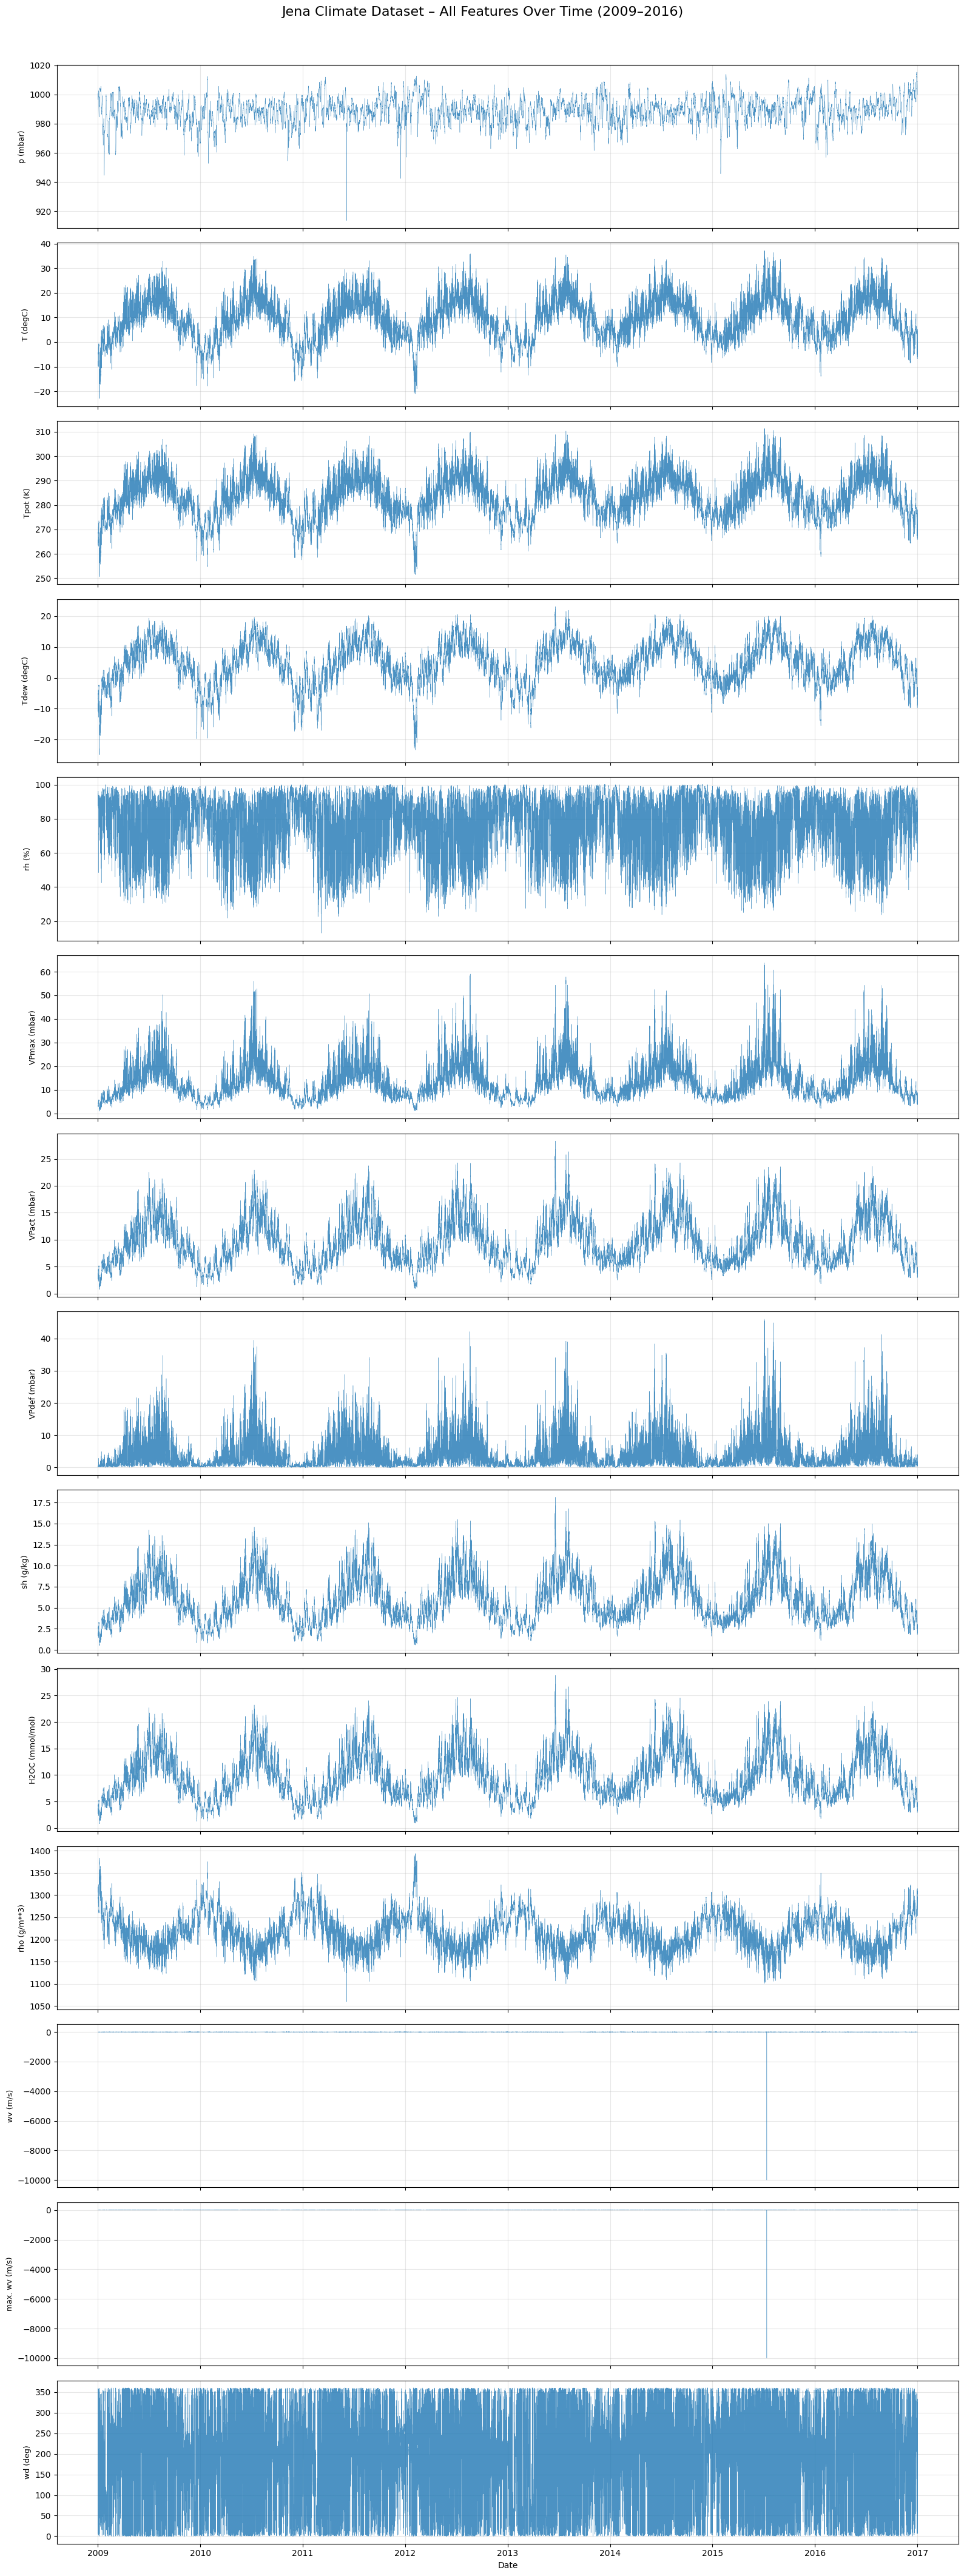

In [4]:
feature_cols = [c for c in df.columns if c != 'Date Time']

fig, axes = plt.subplots(len(feature_cols), 1, figsize=(16, 3 * len(feature_cols)), sharex=True)
fig.suptitle('Jena Climate Dataset – All Features Over Time (2009–2016)', fontsize=16, y=1.01)

for i, col in enumerate(feature_cols):
    axes[i].plot(df['Date Time'], df[col], linewidth=0.3, alpha=0.8)
    axes[i].set_ylabel(col, fontsize=9)
    axes[i].grid(True, alpha=0.3)

axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

Most variables show a strong **yearly seasonality**. Temperature (`T`), potential temperature (`Tpot`), dew point (`Tdew`), vapour pressures (`VPmax`, `VPact`), specific humidity (`sh`) and water-vapour concentration (`H2OC`) all rise every summer and fall every winter.
Pressure (`p`) and relative humidity (`rh`) are seasonal too, with smaller swings. The −9999 spikes in `wv` and `max. wv` stand out clearly.

### 2.3 Temperature Trend Analysis

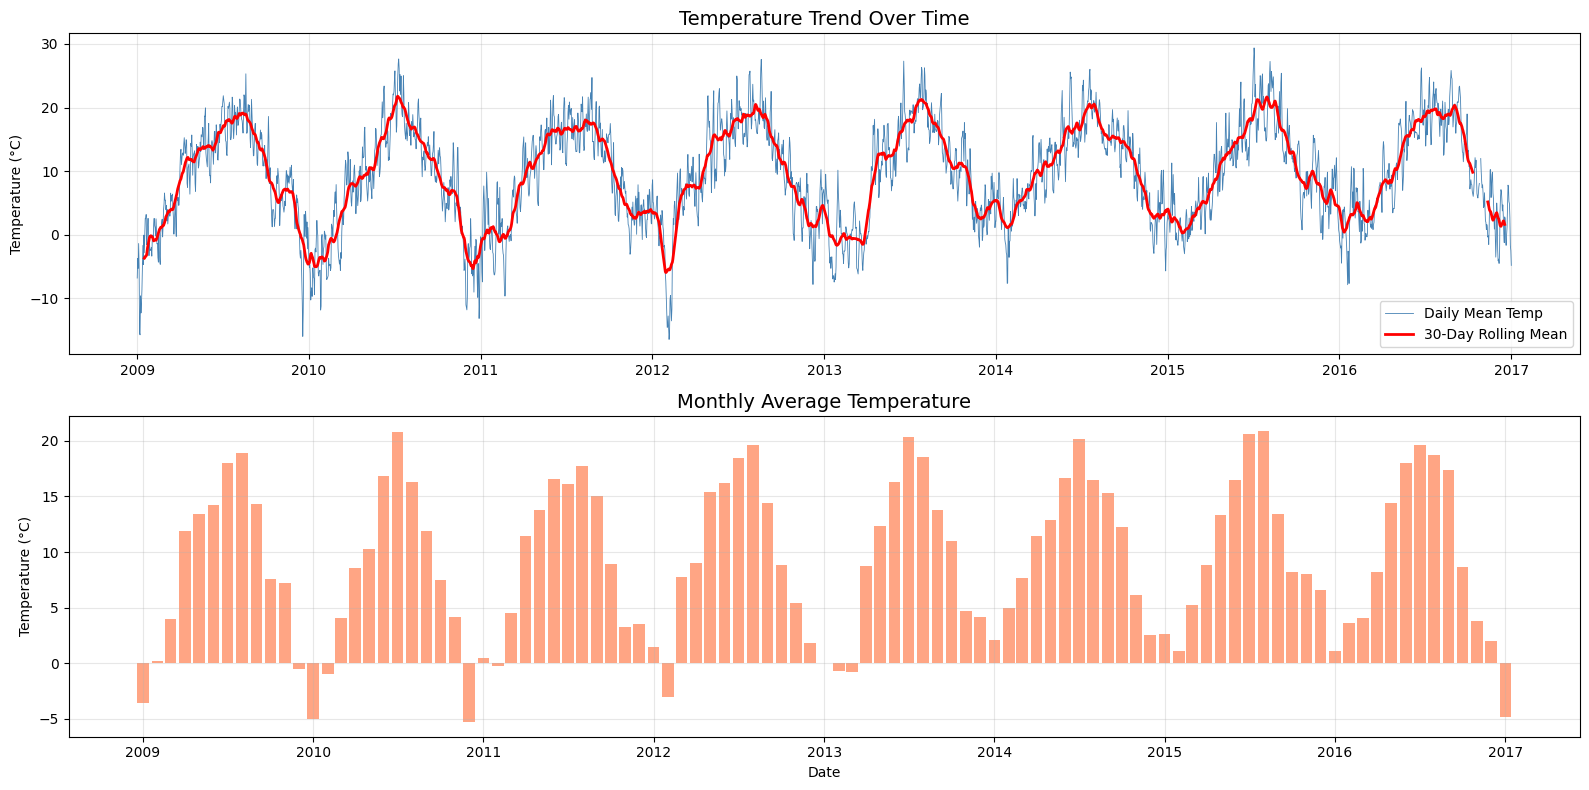

In [5]:
# Resample to daily mean for cleaner trend visualization
df_daily = df.set_index('Date Time').resample('D').mean()

fig, axes = plt.subplots(2, 1, figsize=(16, 8))

# Raw temperature
axes[0].plot(df_daily.index, df_daily['T (degC)'], linewidth=0.6, color='steelblue', label='Daily Mean Temp')
# Rolling 30-day average
rolling_30 = df_daily['T (degC)'].rolling(window=30, center=True).mean()
axes[0].plot(df_daily.index, rolling_30, linewidth=2, color='red', label='30-Day Rolling Mean')
axes[0].set_title('Temperature Trend Over Time', fontsize=14)
axes[0].set_ylabel('Temperature (°C)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Monthly mean temperature to show seasonality
df_monthly = df.set_index('Date Time').resample('MS').mean()
axes[1].bar(df_monthly.index, df_monthly['T (degC)'], width=25, color='coral', alpha=0.7)
axes[1].set_title('Monthly Average Temperature', fontsize=14)
axes[1].set_ylabel('Temperature (°C)')
axes[1].set_xlabel('Date')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Temperature follows a very regular yearly cycle, peaking at about 20–25 °C in mid-summer and dropping to about −10 °C in winter. There is **no significant long-term trend** over 2009–2016.

### 2.4 Seasonality Analysis

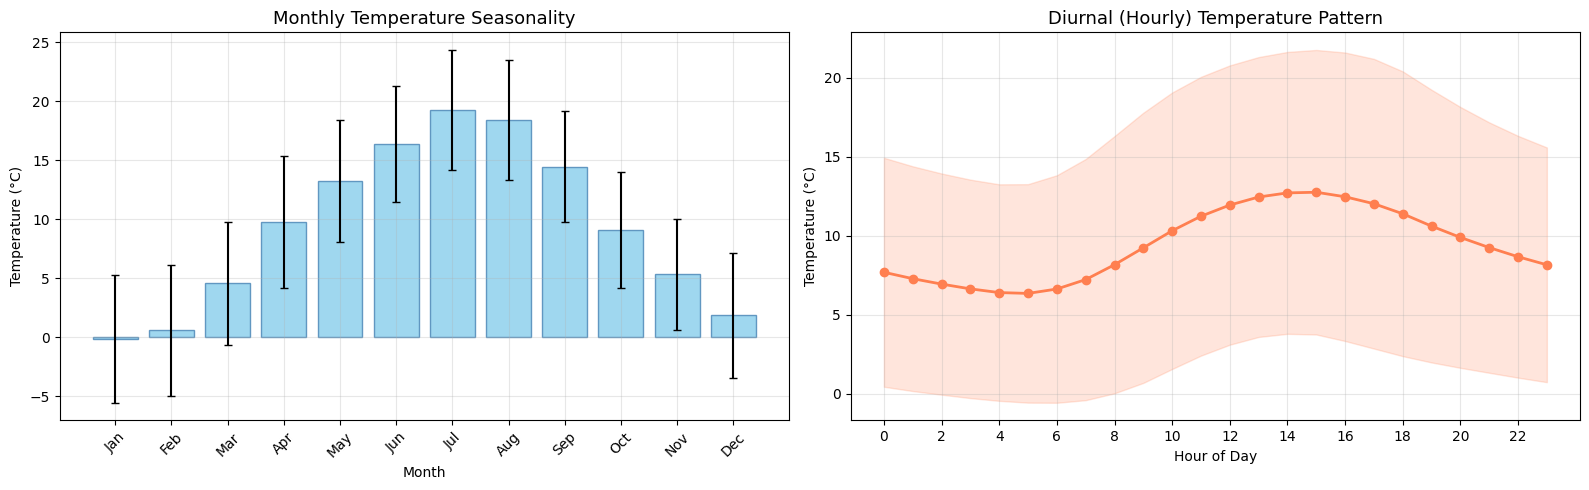

In [6]:
# Extract time components for seasonality analysis
df['month'] = df['Date Time'].dt.month
df['hour'] = df['Date Time'].dt.hour
df['year'] = df['Date Time'].dt.year

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Monthly seasonality
monthly_stats = df.groupby('month')['T (degC)'].agg(['mean', 'std'])
axes[0].bar(monthly_stats.index, monthly_stats['mean'], yerr=monthly_stats['std'],
            capsize=3, color='skyblue', edgecolor='steelblue', alpha=0.8)
axes[0].set_title('Monthly Temperature Seasonality', fontsize=13)
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Temperature (°C)')
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], rotation=45)
axes[0].grid(True, alpha=0.3)

# Hourly (diurnal) pattern
hourly_stats = df.groupby('hour')['T (degC)'].agg(['mean', 'std'])
axes[1].plot(hourly_stats.index, hourly_stats['mean'], 'o-', color='coral', linewidth=2)
axes[1].fill_between(hourly_stats.index,
                      hourly_stats['mean'] - hourly_stats['std'],
                      hourly_stats['mean'] + hourly_stats['std'],
                      alpha=0.2, color='coral')
axes[1].set_title('Diurnal (Hourly) Temperature Pattern', fontsize=13)
axes[1].set_xlabel('Hour of Day')
axes[1].set_ylabel('Temperature (°C)')
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


- **Monthly:** mean temperature rises from about 0 °C in January to a peak of about 19 °C in July, then falls again. Variability is largest in summer.
- **Daily:** temperature is lowest around 4–6 am (about 7 °C) and peaks around 2 pm (about 13 °C), which is the diurnal solar cycle.

Temperature is therefore driven by both the time of year and the time of day, which a model with a 72-hour input window can pick up.

### 2.5 Correlation Analysis

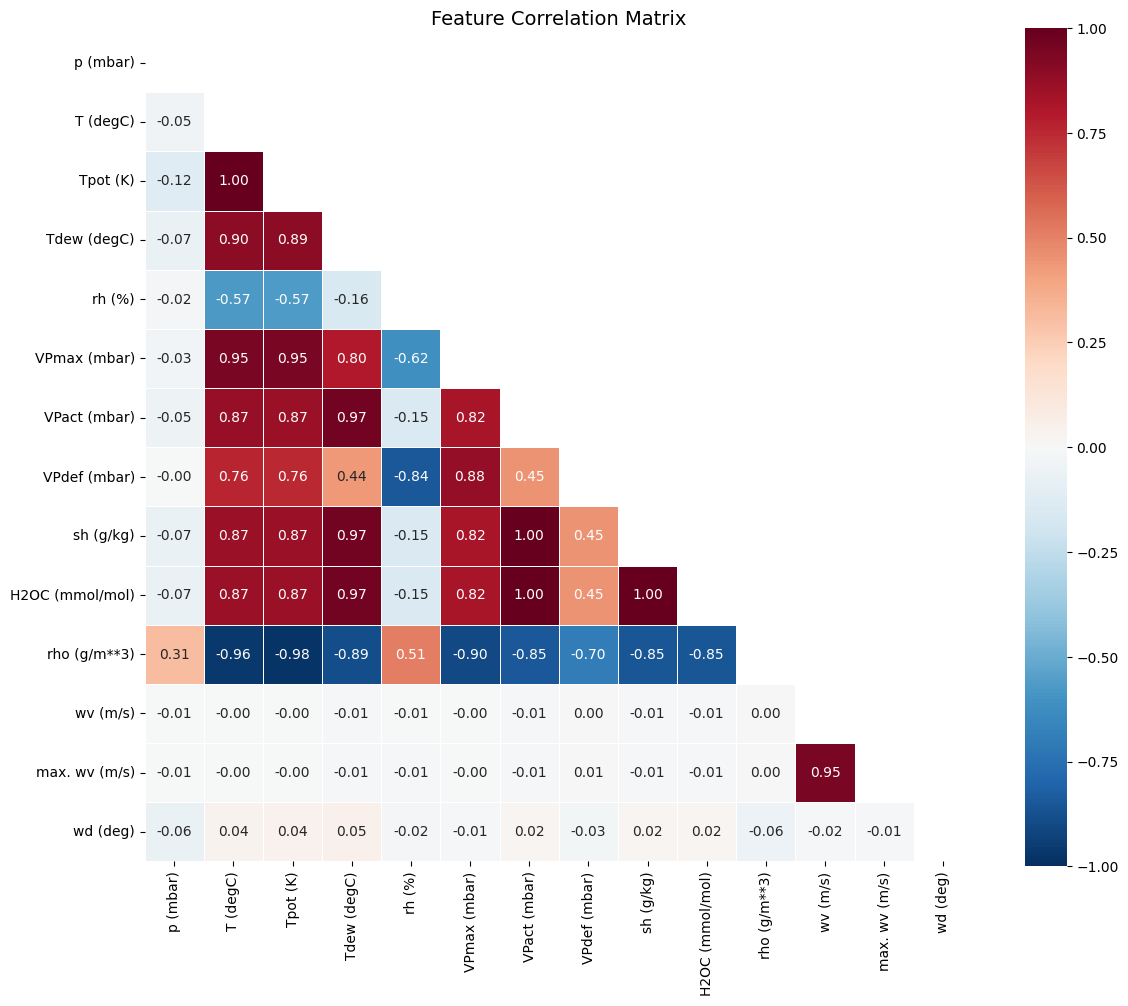


Correlation with Temperature T (degC):
  Tpot (K)                 : +0.9968
  VPmax (mbar)             : +0.9511
  Tdew (degC)              : +0.8957
  VPact (mbar)             : +0.8677
  H2OC (mmol/mol)          : +0.8672
  sh (g/kg)                : +0.8668
  VPdef (mbar)             : +0.7617
  wd (deg)                 : +0.0387
  max. wv (m/s)            : -0.0029
  wv (m/s)                 : -0.0047
  p (mbar)                 : -0.0454
  rh (%)                   : -0.5724
  rho (g/m**3)             : -0.9634


In [7]:
# Correlation heatmap
feature_cols_num = [c for c in df.columns if c not in ['Date Time', 'month', 'hour', 'year']]
corr_matrix = df[feature_cols_num].corr()

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title('Feature Correlation Matrix', fontsize=14)
plt.tight_layout()
plt.show()

# Top correlations with Temperature
temp_corr = corr_matrix['T (degC)'].drop('T (degC)').sort_values(ascending=False)
print("\nCorrelation with Temperature T (degC):")
for feat, val in temp_corr.items():
    print(f"  {feat:25s}: {val:+.4f}")


Temperature correlates almost perfectly with physically derived quantities: `Tpot` (1.00), `VPmax` (0.95), `Tdew` (0.90), and `VPact`, `sh` and `H2OC` (0.87). It correlates strongly negatively with air density `rho` (−0.96, since warm air is less dense) and moderately negatively with relative humidity `rh` (−0.57).

Because those derived variables are near-duplicates of temperature, the model uses a compact set of **independent** inputs instead: pressure, temperature, relative humidity, wind speed and wind direction.

## 3. Preprocessing

In [8]:
# Fix sensor errors: wind speed is sometimes recorded as -9999
for col in ['wv (m/s)', 'max. wv (m/s)']:
    n_bad = (df[col] < 0).sum()
    df.loc[df[col] < 0, col] = 0.0
    print(f"{col}: {n_bad} negative readings set to 0")

# Subsample from 10-minute to hourly resolution
df_hourly = df.iloc[::6].reset_index(drop=True)
print(f"\nOriginal samples: {len(df)}")
print(f"Hourly samples:   {len(df_hourly)}")

wv (m/s): 18 negative readings set to 0
max. wv (m/s): 20 negative readings set to 0

Original samples: 420551
Hourly samples:   70092


At 10-minute resolution, consecutive rows are almost identical, which is redundant for an hourly forecast. The data is **subsampled to one reading per hour** (every 6th row), which also makes training 6× cheaper. The wind-speed sensor errors are clipped to 0 first.

In [9]:
selected_features = ['p (mbar)', 'T (degC)', 'rh (%)', 'wv (m/s)', 'wd (deg)']
target_col = 'T (degC)'

print(f"\nSelected features: {selected_features}")
print(f"Target variable: {target_col}")

data = df_hourly[selected_features].values.astype(np.float32)
print(f"\nData shape after feature selection: {data.shape}")


Selected features: ['p (mbar)', 'T (degC)', 'rh (%)', 'wv (m/s)', 'wd (deg)']
Target variable: T (degC)

Data shape after feature selection: (70092, 5)


Input features: pressure, temperature, humidity, wind speed and wind direction. The target is temperature one hour ahead.

In [10]:
# Split data
n = len(data)
train_end = int(n * 0.7)
val_end = int(n * 0.9)

train_data = data[:train_end]
val_data = data[train_end:val_end]
test_data = data[val_end:]

print(f"Train: {train_data.shape} ({train_data.shape[0]/n*100:.1f}%)")
print(f"Val:   {val_data.shape} ({val_data.shape[0]/n*100:.1f}%)")
print(f"Test:  {test_data.shape} ({test_data.shape[0]/n*100:.1f}%)")

Train: (49064, 5) (70.0%)
Val:   (14018, 5) (20.0%)
Test:  (7010, 5) (10.0%)


The split is **chronological** (70% train / 20% validation / 10% test) with no shuffling, so the model is always evaluated on the future. Shuffling time-series data before splitting would leak future information into training.

In [11]:
# Normalize using StandardScaler
scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_data)
val_scaled = scaler.transform(val_data)
test_scaled = scaler.transform(test_data)

# Get target index
target_idx = selected_features.index(target_col)
print(f"\nTarget column index: {target_idx}")
print(f"Scaler mean (target): {scaler.mean_[target_idx]:.4f}")
print(f"Scaler std  (target): {scaler.scale_[target_idx]:.4f}")


Target column index: 1
Scaler mean (target): 9.1081
Scaler std  (target): 8.6551


Features have very different scales (pressure ≈ 1000 mbar, wind direction 0–360°), so each one is standardised to mean 0 and SD 1. The scaler is **fit on the training set only**.

In [12]:
SEQUENCE_LENGTH = 72  # 72 hours (3 days) of history to predict 1 step ahead
FORECAST_HORIZON = 1  # output sequence length = 1

class TimeSeriesDataset(Dataset):
    """PyTorch Dataset for time-series forecasting."""

    def __init__(self, data, seq_len, target_idx, forecast_horizon=1):
        self.data = torch.FloatTensor(data)
        self.seq_len = seq_len
        self.target_idx = target_idx
        self.forecast_horizon = forecast_horizon

    def __len__(self):
        return len(self.data) - self.seq_len - self.forecast_horizon + 1

    def __getitem__(self, idx):
        x = self.data[idx : idx + self.seq_len]                          # (seq_len, num_features)
        y = self.data[idx + self.seq_len, self.target_idx]               # scalar (single step)
        return x, y

# Create datasets
train_dataset = TimeSeriesDataset(train_scaled, SEQUENCE_LENGTH, target_idx, FORECAST_HORIZON)
val_dataset   = TimeSeriesDataset(val_scaled, SEQUENCE_LENGTH, target_idx, FORECAST_HORIZON)
test_dataset  = TimeSeriesDataset(test_scaled, SEQUENCE_LENGTH, target_idx, FORECAST_HORIZON)

# Create dataloaders
BATCH_SIZE = 128

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

# Verify shapes
x_sample, y_sample = next(iter(train_loader))
print(f"Input batch shape:  {x_sample.shape}  -> (batch, seq_len, features)")
print(f"Target batch shape: {y_sample.shape}  -> (batch,)")
print(f"\nTotal train sequences: {len(train_dataset)}")
print(f"Total val sequences:   {len(val_dataset)}")
print(f"Total test sequences:  {len(test_dataset)}")


Input batch shape:  torch.Size([128, 72, 5])  -> (batch, seq_len, features)
Target batch shape: torch.Size([128])  -> (batch,)

Total train sequences: 48992
Total val sequences:   13946
Total test sequences:  6938


**Sliding windows:** each sample uses 72 consecutive hours (3 days) of all 5 features as input `X`, and the temperature in the next hour as target `y`. The windows slide forward one hour at a time:

```
[hours 1–72]  → predict hour 73
[hours 2–73]  → predict hour 74
...
```
Batches have shape `(128, 72, 5)`: 128 windows × 72 time steps × 5 features.

## 4. Model Architecture

In [13]:
# Check device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
print(f"PyTorch version: {torch.__version__}")


Using device: cpu
PyTorch version: 2.14.0+cu130


In [14]:
class LSTMForecaster(nn.Module):

    def __init__(self, input_size, hidden_size=64, num_layers=2, dropout=0.2):
        super(LSTMForecaster, self).__init__()

        self.hidden_size = hidden_size
        self.num_layers = num_layers

        # Stacked LSTM layers
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        # Fully connected output layer
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        # x shape: (batch, seq_len, input_size)
        lstm_out, (h_n, c_n) = self.lstm(x)

        # Use the last hidden state
        last_hidden = lstm_out[:, -1, :]  # (batch, hidden_size)

        # Predict
        out = self.fc(last_hidden)        # (batch, 1)
        return out.squeeze(-1)            # (batch,)

# Instantiate model
INPUT_SIZE = len(selected_features)  # 5 features
HIDDEN_SIZE = 64
NUM_LAYERS = 2
DROPOUT = 0.2

model = LSTMForecaster(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT
).to(device)

print(model)
print(f"\nTotal parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")


LSTMForecaster(
  (lstm): LSTM(5, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)

Total parameters: 53,569
Trainable parameters: 53,569


**Architecture**
1. **2 stacked LSTM layers** (hidden size 64). The first layer learns short-term patterns and the second combines them into longer-range ones. Dropout of 0.2 between the layers reduces overfitting.
2. **Fully connected head:** the last time step's hidden state (a 64-number summary of the 3-day window) goes through 64 → 32 (ReLU + dropout) → 1 output, the temperature one hour ahead.

About 54k parameters in total.

## 5. Training

In [15]:
def train_model(model, train_loader, val_loader, epochs=30, lr=1e-3, patience=5):
    """Train the model with early stopping."""
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3) # halve the LR when val loss plateaus

    train_losses = []
    val_losses = []
    best_val_loss = float('inf')
    patience_counter = 0
    best_model_state = None

    for epoch in range(epochs):
        # --- Training ---
        model.train()
        epoch_train_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            optimizer.zero_grad() # reset gradients
            y_pred = model(X_batch) # forward pass
            loss = criterion(y_pred, y_batch) # compute loss
            loss.backward() # backpropagation
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0) # clip gradients to avoid exploding gradients
            optimizer.step()  # update weights

            epoch_train_loss += loss.item() * X_batch.size(0)

        avg_train_loss = epoch_train_loss / len(train_loader.dataset)
        train_losses.append(avg_train_loss)

        # --- Validation ---
        model.eval()
        epoch_val_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                y_pred = model(X_batch)
                loss = criterion(y_pred, y_batch)
                epoch_val_loss += loss.item() * X_batch.size(0)

        avg_val_loss = epoch_val_loss / len(val_loader.dataset)
        val_losses.append(avg_val_loss)

        scheduler.step(avg_val_loss)

        # Early stopping
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            patience_counter = 0
            best_model_state = copy.deepcopy(model.state_dict())  # deep copy, otherwise it keeps changing
        else:
            patience_counter += 1

        if (epoch + 1) % 2 == 0 or epoch == 0:
            print(f"Epoch [{epoch+1:3d}/{epochs}] | "
                  f"Train Loss: {avg_train_loss:.6f} | "
                  f"Val Loss: {avg_val_loss:.6f} | "
                  f"Patience: {patience_counter}/{patience}")

        if patience_counter >= patience:
            print(f"\nEarly stopping at epoch {epoch+1}")
            break

    # Load best model
    model.load_state_dict(best_model_state)
    print(f"\nBest validation loss: {best_val_loss:.6f}")
    return train_losses, val_losses


**Training loop**
- MSE loss with the Adam optimiser.
- **Gradient clipping** (max norm 1.0) to prevent the exploding gradients common in RNNs.
- **ReduceLROnPlateau** halves the learning rate when validation loss stalls.
- **Early stopping** (patience 7) keeps the weights with the best validation loss. These are deep-copied, because `state_dict()` returns references that keep changing during training.

In [16]:
# Train the model
EPOCHS = 30
LEARNING_RATE = 1e-3
PATIENCE = 7

print("=" * 60)
print("Training Baseline LSTM Model")
print("=" * 60)
train_losses, val_losses = train_model(
    model, train_loader, val_loader,
    epochs=EPOCHS, lr=LEARNING_RATE, patience=PATIENCE
)


Training Baseline LSTM Model


Epoch [  1/30] | Train Loss: 0.128977 | Val Loss: 0.016993 | Patience: 0/7


Epoch [  2/30] | Train Loss: 0.042250 | Val Loss: 0.013779 | Patience: 0/7


Epoch [  4/30] | Train Loss: 0.032951 | Val Loss: 0.008245 | Patience: 0/7


Epoch [  6/30] | Train Loss: 0.029663 | Val Loss: 0.009472 | Patience: 1/7


...

Epoch [ 22/30] | Train Loss: 0.026135 | Val Loss: 0.007730 | Patience: 4/7


Epoch [ 24/30] | Train Loss: 0.025391 | Val Loss: 0.006788 | Patience: 1/7


Epoch [ 26/30] | Train Loss: 0.025530 | Val Loss: 0.007335 | Patience: 3/7


Epoch [ 28/30] | Train Loss: 0.026005 | Val Loss: 0.007292 | Patience: 1/7


Epoch [ 30/30] | Train Loss: 0.025820 | Val Loss: 0.007148 | Patience: 3/7

Best validation loss: 0.006365


Training loss drops sharply in the first two epochs as the model picks up the basic daily and seasonal patterns, then decreases slowly. Validation loss keeps improving with some epoch-to-epoch noise, and the best checkpoint is restored at the end.

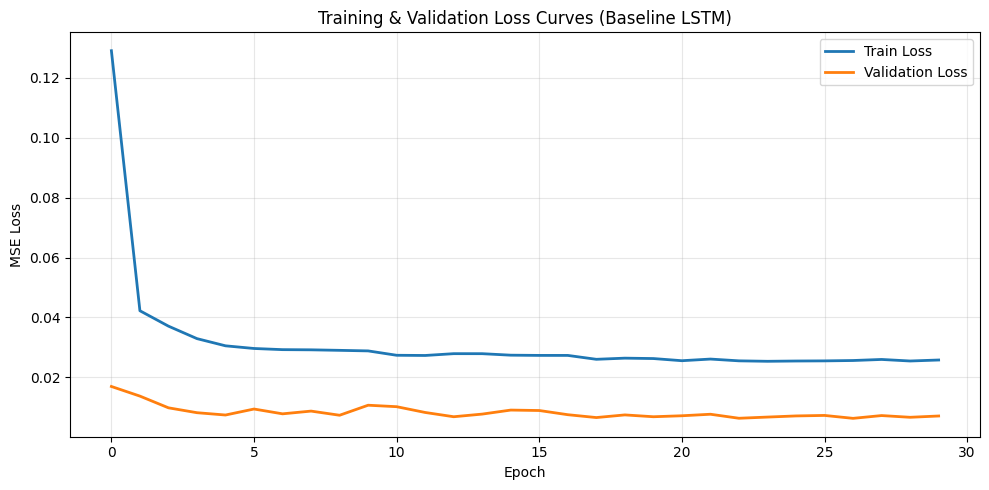

In [17]:
# Plot training curves
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(train_losses, label='Train Loss', linewidth=2)
ax.plot(val_losses, label='Validation Loss', linewidth=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE Loss')
ax.set_title('Training & Validation Loss Curves (Baseline LSTM)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Validation loss sits **below** training loss throughout. This is expected: dropout is active during training, which makes training harder, and switched off during validation. The two curves decrease together without diverging, so there is no sign of overfitting.

## 6. Evaluation

In [18]:
def evaluate_model(model, data_loader, scaler, target_idx):
    """Evaluate model and return actual vs predicted values in original scale."""
    model.eval()
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(device)
            y_pred = model(X_batch)
            all_preds.append(y_pred.cpu().numpy())
            all_targets.append(y_batch.numpy())

    preds = np.concatenate(all_preds)
    targets = np.concatenate(all_targets)

    # Inverse transform: convert from scaled to original values
    # y_original = y_scaled * std + mean
    target_mean = scaler.mean_[target_idx]
    target_std = scaler.scale_[target_idx]

    preds_orig = preds * target_std + target_mean
    targets_orig = targets * target_std + target_mean

    return preds_orig, targets_orig

def print_metrics(y_true, y_pred, label=""):
    """Print evaluation metrics."""
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"\n{'='*40}")
    print(f"  {label} Evaluation Metrics")
    print(f"{'='*40}")
    print(f"  MAE  : {mae:.4f} °C")
    print(f"  RMSE : {rmse:.4f} °C")
    print(f"  R²   : {r2:.4f}")
    return mae, rmse, r2


In [19]:
test_preds, test_targets = evaluate_model(model, test_loader, scaler, target_idx)
baseline_mae, baseline_rmse, baseline_r2 = print_metrics(test_targets, test_preds, label="Baseline LSTM (Test)")

# Evaluate on VALIDATION set
val_preds, val_targets = evaluate_model(model, val_loader, scaler, target_idx)
_ = print_metrics(val_targets, val_preds, label="Baseline LSTM (Validation)")


  Baseline LSTM (Test) Evaluation Metrics
  MAE  : 0.4839 °C
  RMSE : 0.6937 °C
  R²   : 0.9921



  Baseline LSTM (Validation) Evaluation Metrics
  MAE  : 0.4771 °C
  RMSE : 0.6905 °C
  R²   : 0.9918


**MAE ≈ 0.48 °C** means next-hour predictions are off by about half a degree on average. RMSE (≈ 0.69 °C) is a bit higher, because a few sudden temperature changes produce larger errors. Test and validation scores are almost identical, so the model generalises consistently to unseen periods.

### 6.1 Is the LSTM actually better than a naive forecast?

Hourly temperature is strongly autocorrelated, so a high R² alone proves little. A fair check compares the model with two no-skill baselines on exactly the same test targets:
- **Persistence:** next hour's temperature equals the current temperature.
- **Seasonal naive:** next hour's temperature equals the temperature 24 hours earlier.

In [20]:
# Naive baselines computed on the same test windows (original °C scale).
# Window i uses hours [i, i+72) as input and predicts hour i+72.
n_test = len(test_data)
persist_preds  = test_data[SEQUENCE_LENGTH - 1 : n_test - 1, target_idx]   # "next hour = this hour"
seasonal_preds = test_data[SEQUENCE_LENGTH - 24 : n_test - 24, target_idx] # "next hour = same hour yesterday"
naive_targets  = test_data[SEQUENCE_LENGTH:, target_idx]
assert np.allclose(naive_targets, test_targets, atol=1e-3)  # same targets, same order

persist_mae, persist_rmse, persist_r2 = print_metrics(naive_targets, persist_preds, label="Persistence (t+1 = t)")
seasonal_mae, seasonal_rmse, seasonal_r2 = print_metrics(naive_targets, seasonal_preds, label="Seasonal naive (t-24h)")


  Persistence (t+1 = t) Evaluation Metrics
  MAE  : 0.7446 °C
  RMSE : 1.0405 °C
  R²   : 0.9823

  Seasonal naive (t-24h) Evaluation Metrics
  MAE  : 2.3789 °C
  RMSE : 3.0960 °C
  R²   : 0.8430


### 6.2 Prediction Visualisation

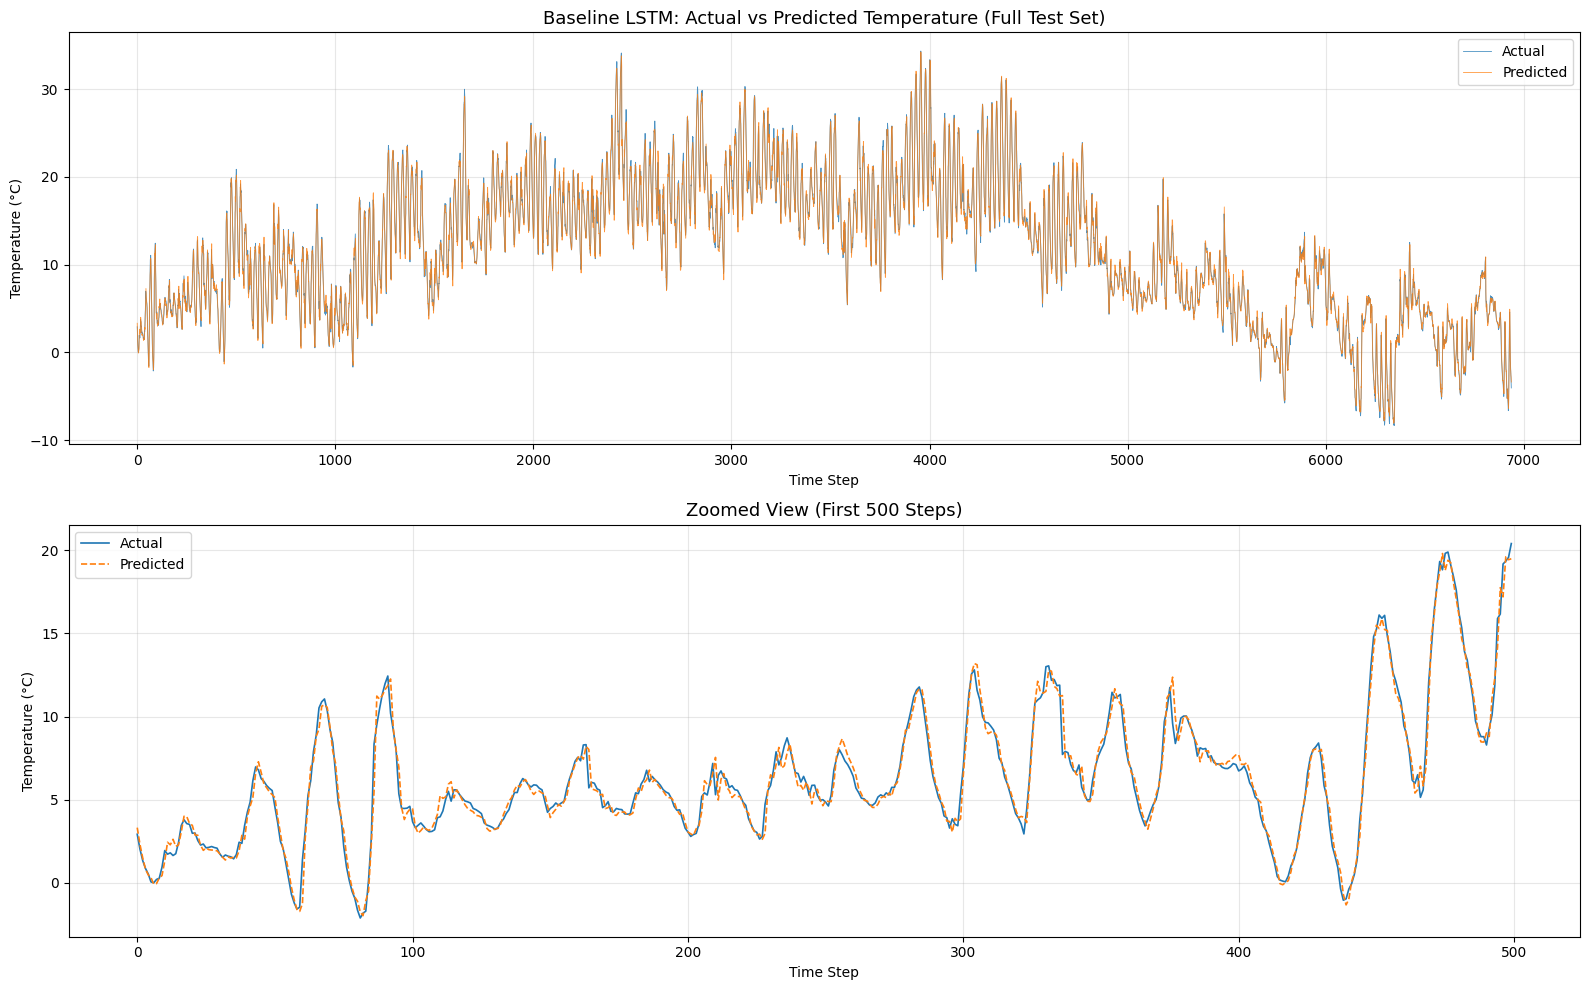

In [21]:
# Plot actual vs predicted on test set
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Full test set
axes[0].plot(test_targets, label='Actual', linewidth=0.6, alpha=0.8)
axes[0].plot(test_preds, label='Predicted', linewidth=0.6, alpha=0.8)
axes[0].set_title('Baseline LSTM: Actual vs Predicted Temperature (Full Test Set)', fontsize=13)
axes[0].set_xlabel('Time Step')
axes[0].set_ylabel('Temperature (°C)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Zoomed-in (first 500 steps)
zoom = 500
axes[1].plot(test_targets[:zoom], label='Actual', linewidth=1.2)
axes[1].plot(test_preds[:zoom], label='Predicted', linewidth=1.2, linestyle='--')
axes[1].set_title(f'Zoomed View (First {zoom} Steps)', fontsize=13)
axes[1].set_xlabel('Time Step')
axes[1].set_ylabel('Temperature (°C)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


The top panel shows the whole test period: the predicted curve almost completely overlaps the actual curve. The zoomed panel shows that the model tracks the daily cycle closely and lags slightly only at abrupt temperature changes.

### 6.3 Error Distribution

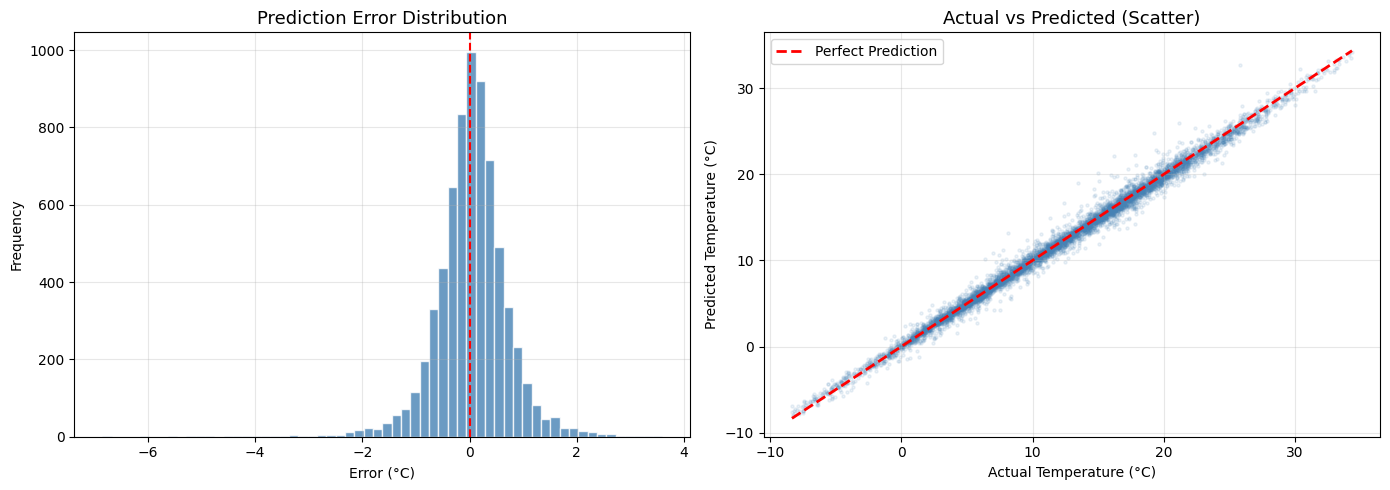

Mean Error: 0.0407 °C
Std of Error: 0.6925 °C


In [22]:
errors = test_targets - test_preds

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(errors, bins=60, color='steelblue', edgecolor='white', alpha=0.8)
axes[0].axvline(x=0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('Prediction Error Distribution', fontsize=13)
axes[0].set_xlabel('Error (°C)')
axes[0].set_ylabel('Frequency')
axes[0].grid(True, alpha=0.3)

# Scatter: actual vs predicted
axes[1].scatter(test_targets, test_preds, alpha=0.1, s=5, color='steelblue')
min_val = min(test_targets.min(), test_preds.min())
max_val = max(test_targets.max(), test_preds.max())
axes[1].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')
axes[1].set_title('Actual vs Predicted (Scatter)', fontsize=13)
axes[1].set_xlabel('Actual Temperature (°C)')
axes[1].set_ylabel('Predicted Temperature (°C)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Mean Error: {errors.mean():.4f} °C")
print(f"Std of Error: {errors.std():.4f} °C")

- **Error histogram:** symmetric and centred on zero, with a mean error of about 0.04 °C, so there is no systematic over- or under-prediction. Most errors fall within ±1 °C, with rare outliers during extreme swings.
- **Actual vs predicted:** points lie tightly along the diagonal across the whole range from −10 °C to 35 °C, with no temperature band where the model breaks down.

## 7. Bidirectional LSTM

Does reading each 72-hour window in both directions help? The input window contains only past data, so a BiLSTM does **not** leak future information. It simply processes the same history forwards and backwards.

In [23]:
class BiLSTMForecaster(nn.Module):
    """Bidirectional LSTM model for time-series forecasting."""

    def __init__(self, input_size, hidden_size=64, num_layers=2, dropout=0.2):
        super(BiLSTMForecaster, self).__init__()

        self.hidden_size = hidden_size
        self.num_layers = num_layers

        # Bidirectional LSTM
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=True  # reads the window forwards and backwards
        )

        # Note: bidirectional doubles the output size
        self.fc = nn.Sequential(
            nn.Linear(hidden_size * 2, 32),  # hidden_size * 2 for bidirectional
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        last_hidden = lstm_out[:, -1, :]  # (batch, hidden_size * 2)
        out = self.fc(last_hidden)
        return out.squeeze(-1)

# Instantiate bidirectional model
bi_model = BiLSTMForecaster(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT
).to(device)

print(bi_model)
print(f"\nTotal parameters: {sum(p.numel() for p in bi_model.parameters()):,}")
print(f"(Baseline had: {sum(p.numel() for p in model.parameters()):,} parameters)")


BiLSTMForecaster(
  (lstm): LSTM(5, 64, num_layers=2, batch_first=True, dropout=0.2, bidirectional=True)
  (fc): Sequential(
    (0): Linear(in_features=128, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)

Total parameters: 139,841
(Baseline had: 53,569 parameters)


Changes from the baseline:
1. `bidirectional=True`: the window is read forwards and backwards and the two hidden states are concatenated.
2. The first dense layer therefore takes 64 × 2 = 128 inputs. The model has 2.6× the parameters of the baseline (140k vs 54k).

In [24]:
# Train Bidirectional LSTM
print("=" * 60)
print("Training Bidirectional LSTM Model")
print("=" * 60)
bi_train_losses, bi_val_losses = train_model(
    bi_model, train_loader, val_loader,
    epochs=EPOCHS, lr=LEARNING_RATE, patience=PATIENCE
)

Training Bidirectional LSTM Model


Epoch [  1/30] | Train Loss: 0.094580 | Val Loss: 0.015307 | Patience: 0/7


Epoch [  2/30] | Train Loss: 0.032981 | Val Loss: 0.010212 | Patience: 0/7


Epoch [  4/30] | Train Loss: 0.029796 | Val Loss: 0.008587 | Patience: 0/7


Epoch [  6/30] | Train Loss: 0.028849 | Val Loss: 0.007988 | Patience: 0/7


...

Epoch [ 20/30] | Train Loss: 0.025783 | Val Loss: 0.006925 | Patience: 5/7


Epoch [ 22/30] | Train Loss: 0.025918 | Val Loss: 0.006361 | Patience: 1/7


Epoch [ 24/30] | Train Loss: 0.026124 | Val Loss: 0.006580 | Patience: 3/7


Epoch [ 26/30] | Train Loss: 0.025273 | Val Loss: 0.006308 | Patience: 5/7


Epoch [ 28/30] | Train Loss: 0.025638 | Val Loss: 0.006659 | Patience: 7/7

Early stopping at epoch 28

Best validation loss: 0.006274


The BiLSTM converges similarly, reaching a slightly lower best validation loss.

In [25]:
# Evaluate Bidirectional model
bi_test_preds, bi_test_targets = evaluate_model(bi_model, test_loader, scaler, target_idx)
bi_mae, bi_rmse, bi_r2 = print_metrics(bi_test_targets, bi_test_preds, label="Bidirectional LSTM (Test)")


  Bidirectional LSTM (Test) Evaluation Metrics
  MAE  : 0.4770 °C
  RMSE : 0.6846 °C
  R²   : 0.9923


The BiLSTM is only **marginally** better (MAE 0.477 vs 0.484 °C). That is a gain of under 0.01 °C for 2.6× the parameters and roughly double the training time, so the simpler baseline is the more sensible choice in practice.

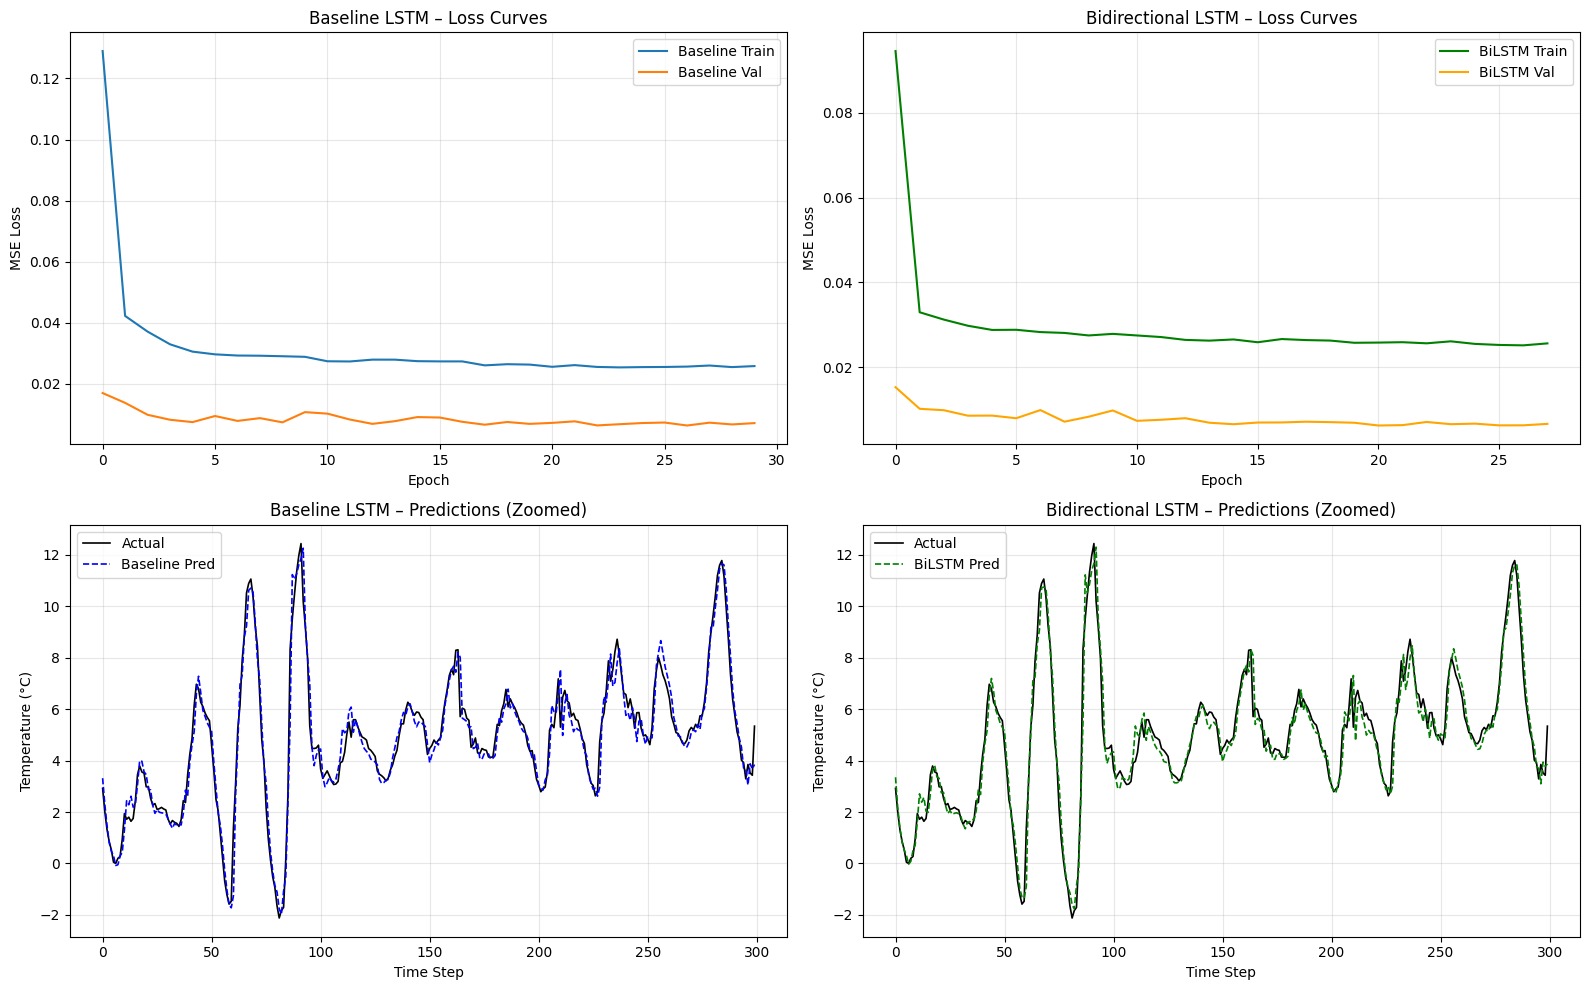


  PERFORMANCE COMPARISON: Baseline vs Bidirectional LSTM
Metric         Baseline LSTM          BiLSTM      Difference
------------------------------------------------------------
MAE (°C)              0.4839          0.4770         -0.0069
RMSE (°C)             0.6937          0.6846         -0.0091
R²                    0.9921          0.9923         +0.0002
------------------------------------------------------------

 Bidirectional LSTM performs BETTER (lower MAE).


In [26]:
# Side-by-side comparison
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Training curves comparison
axes[0, 0].plot(train_losses, label='Baseline Train', linewidth=1.5)
axes[0, 0].plot(val_losses, label='Baseline Val', linewidth=1.5)
axes[0, 0].set_title('Baseline LSTM – Loss Curves')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('MSE Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(bi_train_losses, label='BiLSTM Train', linewidth=1.5, color='green')
axes[0, 1].plot(bi_val_losses, label='BiLSTM Val', linewidth=1.5, color='orange')
axes[0, 1].set_title('Bidirectional LSTM – Loss Curves')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('MSE Loss')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Predictions comparison (zoomed)
zoom = 300
axes[1, 0].plot(test_targets[:zoom], label='Actual', linewidth=1.2, color='black')
axes[1, 0].plot(test_preds[:zoom], label='Baseline Pred', linewidth=1.2, linestyle='--', color='blue')
axes[1, 0].set_title('Baseline LSTM – Predictions (Zoomed)')
axes[1, 0].set_xlabel('Time Step')
axes[1, 0].set_ylabel('Temperature (°C)')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(bi_test_targets[:zoom], label='Actual', linewidth=1.2, color='black')
axes[1, 1].plot(bi_test_preds[:zoom], label='BiLSTM Pred', linewidth=1.2, linestyle='--', color='green')
axes[1, 1].set_title('Bidirectional LSTM – Predictions (Zoomed)')
axes[1, 1].set_xlabel('Time Step')
axes[1, 1].set_ylabel('Temperature (°C)')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Metrics comparison table
print("\n" + "=" * 60)
print("  PERFORMANCE COMPARISON: Baseline vs Bidirectional LSTM")
print("=" * 60)
print(f"{'Metric':<12} {'Baseline LSTM':>15} {'BiLSTM':>15} {'Difference':>15}")
print("-" * 60)
print(f"{'MAE (°C)':<12} {baseline_mae:>15.4f} {bi_mae:>15.4f} {bi_mae - baseline_mae:>+15.4f}")
print(f"{'RMSE (°C)':<12} {baseline_rmse:>15.4f} {bi_rmse:>15.4f} {bi_rmse - baseline_rmse:>+15.4f}")
print(f"{'R²':<12} {baseline_r2:>15.4f} {bi_r2:>15.4f} {bi_r2 - baseline_r2:>+15.4f}")
print("-" * 60)

if bi_mae < baseline_mae:
    print("\n Bidirectional LSTM performs BETTER (lower MAE).")
else:
    print("\n Bidirectional LSTM does NOT outperform the baseline.")


In [27]:
summary = pd.DataFrame({
    'Model': ['Seasonal naive (t-24h)', 'Persistence (t+1 = t)', 'Baseline LSTM', 'Bidirectional LSTM'],
    'MAE (°C)':  [seasonal_mae, persist_mae, baseline_mae, bi_mae],
    'RMSE (°C)': [seasonal_rmse, persist_rmse, baseline_rmse, bi_rmse],
    'R²':        [seasonal_r2, persist_r2, baseline_r2, bi_r2],
}).round(4)
summary

,Model,MAE (°C),RMSE (°C),R²
0,Seasonal naive (t-24h),2.3789,3.0960,0.8430
1,Persistence (t+1 = t),0.7446,1.0405,0.9823
2,Baseline LSTM,0.4839,0.6937,0.9921
3,Bidirectional LSTM,0.4770,0.6846,0.9923


## 8. Conclusions

| Model | MAE (°C) | RMSE (°C) | R² |
|---|---|---|---|
| Seasonal naive (same hour yesterday) | 2.38 | 3.10 | 0.843 |
| Persistence (next hour = this hour) | 0.74 | 1.04 | 0.982 |
| **Stacked LSTM** | **0.48** | **0.69** | **0.992** |
| Bidirectional LSTM | 0.48 | 0.68 | 0.992 |

- The **persistence baseline already reaches R² = 0.98**, so a high R² alone says little for hourly temperature. The meaningful comparison is against the baselines: the LSTM cuts MAE by **35%** vs persistence (0.74 → 0.48 °C) and RMSE by 33%.
- The bidirectional variant adds 2.6× the parameters for a negligible gain, so the stacked LSTM is the better trade-off.
- **Next steps:** multi-step forecasts (e.g. 24 hours ahead), where persistence breaks down and learned models matter more; cyclical time features (sin/cos of hour and day of year); and comparison with a gradient-boosting model on lag features.